# Rossmann Store Sales

Задача исследования - изучить историю ежедневных продаж магазинов и определить проблемы, которые необходимо учитывать при настройке AutoML для прогноза будущей выручки.

Источник: [Rossmann Store Sales (Kaggle)](https://www.kaggle.com/competitions/rossmann-store-sales/data). Расчёты выполняются по файлам `train.csv`, `test.csv` и `store.csv` из архива [rossmann-store-sales.zip](https://drive.google.com/file/d/12tVUQVPZiZdlGXGncHISBiwjIJu8ygLz/view?usp=drive_link).

## 1. Первичный анализ

Проверяются состав архива, структура таблиц, типы данных и связи между продажами и характеристиками магазинов.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from zipfile import ZipFile
from IPython.display import display

sns.set_theme(style="whitegrid")
archive = ZipFile("rossmann-store-sales.zip")
print("Файлы архива:", archive.namelist())

Файлы архива: ['sample_submission.csv', 'store.csv', 'test.csv', 'train.csv']


In [4]:
train = pd.read_csv(archive.open("train.csv"), low_memory=False)
test = pd.read_csv(archive.open("test.csv"), low_memory=False)
store = pd.read_csv(archive.open("store.csv"), low_memory=False)

train["Date"] = pd.to_datetime(train["Date"], errors="coerce")
test["Date"] = pd.to_datetime(test["Date"], errors="coerce")

for name, df in [("train", train), ("test", test), ("store", store)]:
    print(name, df.shape)
    display(df.head(3))

train (1017209, 9)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1


test (41088, 8)


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0


store (1115, 10)


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"


In [5]:
print("Типы признаков train:")
display(train.dtypes.value_counts().to_frame("Количество"))
print("Типы признаков store:")
display(store.dtypes.value_counts().to_frame("Количество"))
print("Период train:", train["Date"].min(), train["Date"].max())
print("Период test:", test["Date"].min(), test["Date"].max())

Типы признаков train:


,Количество
int64,7
datetime64[us],1
str,1


Типы признаков store:


,Количество
float64,5
str,3
int64,2


Период train: 2013-01-01 00:00:00 2015-07-31 00:00:00
Период test: 2015-08-01 00:00:00 2015-09-17 00:00:00


`Sales` - дневная выручка магазина, `Customers` - фактическое число покупателей. Таблица `store.csv` описывает магазины и присоединяется по `Store`. Перед объединением проверяются ключи.

In [6]:
for name, df in [("train", train), ("test", test)]:
    print(name, "повторов Store-Date:", df.duplicated(["Store", "Date"]).sum())
    print(name, "неизвестных дат:", df["Date"].isna().sum())

print("Повторов Store в справочнике:", store["Store"].duplicated().sum())
print("Магазинов train:", train["Store"].nunique())
print("Магазинов test:", test["Store"].nunique())
print("Магазинов только в test:", len(set(test["Store"]) - set(train["Store"])))

train повторов Store-Date: 0
train неизвестных дат: 0
test повторов Store-Date: 0
test неизвестных дат: 0
Повторов Store в справочнике: 0
Магазинов train: 1115
Магазинов test: 856
Магазинов только в test: 0


In [7]:
train_full = train.merge(store, on="Store", how="left", validate="many_to_one", indicator=True)
print("Соответствие магазинов справочнику:")
print(train_full["_merge"].value_counts())
train_full = train_full.drop(columns="_merge")
print("Строк после объединения:", len(train_full))

Соответствие магазинов справочнику:
_merge
both          1017209
left_only           0
right_only          0
Name: count, dtype: int64
Строк после объединения: 1017209


## 2. Целевая переменная и продажи

Проверяются распределение `Sales`, нулевые продажи и различия между магазинами. Для прогноза будущего дня фактическая выручка является неизвестным результатом.

In [8]:
display(train["Sales"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))
print("Нулевых продаж:", (train["Sales"] == 0).sum())
print("Отрицательных продаж:", (train["Sales"] < 0).sum())
print("Максимальная выручка:", train["Sales"].max())

count    1017209.00
mean        5773.82
std         3849.93
min            0.00
50%         5744.00
90%        10288.00
95%        12137.00
99%        17160.00
max        41551.00
Name: Sales, dtype: float64

Нулевых продаж: 172871
Отрицательных продаж: 0
Максимальная выручка: 41551


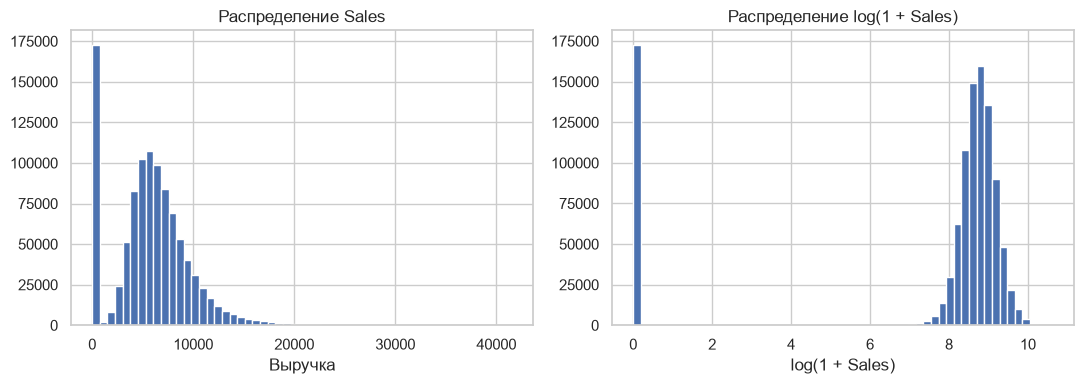

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(train["Sales"], bins=55)
ax[0].set_title("Распределение Sales")
ax[0].set_xlabel("Выручка")
ax[1].hist(np.log1p(train.loc[train["Sales"] >= 0, "Sales"]), bins=55)
ax[1].set_title("Распределение log(1 + Sales)")
ax[1].set_xlabel("log(1 + Sales)")
plt.tight_layout()
plt.show()

In [10]:
store_sales = train.groupby("Store")["Sales"].agg(["size", "mean", "median"])
display(store_sales.describe().round(2))
print("Магазинов с хотя бы одной нулевой продажей:",
      train.loc[train["Sales"] == 0, "Store"].nunique())

,size,mean,median
count,1115.00,1115.00,1115.00
mean,912.30,5763.32,6209.22
std,67.73,2046.45,2217.44
min,758.00,2244.50,2028.50
25%,942.00,4412.42,4711.50
50%,942.00,5459.19,5843.00
75%,942.00,6633.87,7135.75
max,942.00,20718.52,20914.00


Магазинов с хотя бы одной нулевой продажей: 1105


## 3. Пропуски, специальные значения и согласованность

Проверяется полнота всех столбцов трёх таблиц. Пропуски в сведениях о Promo2 и конкурентах рассматриваются с учётом смысла соответствующих полей.

In [11]:
for name, df in [("train", train), ("test", test), ("store", store)]:
    missing = (100 * df.isna().mean()).sort_values(ascending=False)
    print("\n", name, "- признаки с пропусками:")
    display(missing[missing > 0].round(2).to_frame("Пропуски, %"))
    empty = df.columns[df.isna().all()].tolist()
    constant = [c for c in df.columns if df[c].nunique(dropna=True) == 1]
    print("Полностью пустые:", empty)
    print("Постоянные:", constant)


 train - признаки с пропусками:


,"Пропуски, %"


Полностью пустые: []
Постоянные: []

 test - признаки с пропусками:


,"Пропуски, %"
Open,0.03


Полностью пустые: []
Постоянные: []

 store - признаки с пропусками:


,"Пропуски, %"
PromoInterval,48.79
Promo2SinceYear,48.79
Promo2SinceWeek,48.79
CompetitionOpenSinceYear,31.75
CompetitionOpenSinceMonth,31.75
CompetitionDistance,0.27


Полностью пустые: []
Постоянные: []


In [12]:
promo_fields = ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]
print("Магазины по участию в Promo2:")
print(store["Promo2"].value_counts(dropna=False))
print("Пропуски признаков Promo2 в зависимости от участия, %:")
display(store.groupby("Promo2")[promo_fields].agg(lambda x: round(100 * x.isna().mean(), 2)))

Магазины по участию в Promo2:
Promo2
1    571
0    544
Name: count, dtype: int64
Пропуски признаков Promo2 в зависимости от участия, %:


,Promo2SinceWeek,Promo2SinceYear,PromoInterval
Promo2,,,
0,100.0,100.0,100.0
1,0.0,0.0,0.0


In [13]:
print("Полные дубликаты train:", train.duplicated().sum())
print("Полные дубликаты test:", test.duplicated().sum())
print("Полные дубликаты store:", store.duplicated().sum())
print("Дни с Open=1 и Sales=0:", ((train["Open"] == 1) & (train["Sales"] == 0)).sum())
print("Дни с Open=0 и Sales>0:", ((train["Open"] == 0) & (train["Sales"] > 0)).sum())
print("Open=1, Sales=0, Customers>0:",
      ((train["Open"] == 1) & (train["Sales"] == 0) & (train["Customers"] > 0)).sum())

Полные дубликаты train: 0
Полные дубликаты test: 0
Полные дубликаты store: 0
Дни с Open=1 и Sales=0: 54
Дни с Open=0 и Sales>0: 0
Open=1, Sales=0, Customers>0: 2


In [14]:
print("Нулевые продажи в зависимости от Open:")
display(pd.crosstab(train["Open"], train["Sales"] == 0))
print("Количество открытых магазинов с нулевыми продажами:",
      train.loc[(train["Open"] == 1) & (train["Sales"] == 0), "Store"].nunique())

Нулевые продажи в зависимости от Open:


Sales,False,True
Open,,
0,0,172817
1,844338,54


Количество открытых магазинов с нулевыми продажами: 41


In [15]:
print("Пропуски Open в test:", test["Open"].isna().sum())
display(test.loc[test["Open"].isna(), ["Store", "Date", "Open", "Promo"]].head(20))
print("Отрицательные Customers:", (train["Customers"] < 0).sum())
print("Open=0 и Customers>0:", ((train["Open"] == 0) & (train["Customers"] > 0)).sum())

Пропуски Open в test: 11


,Store,Date,Open,Promo
479,622,2015-09-17,NaN,1
1335,622,2015-09-16,NaN,1
2191,622,2015-09-15,NaN,1
3047,622,2015-09-14,NaN,1
4759,622,2015-09-12,NaN,0
5615,622,2015-09-11,NaN,0
6471,622,2015-09-10,NaN,0
7327,622,2015-09-09,NaN,0
8183,622,2015-09-08,NaN,0
9039,622,2015-09-07,NaN,0


Отрицательные Customers: 0
Open=0 и Customers>0: 0


## 4. Категории и распределения признаков

Изучаются тип магазина, ассортимент, акции, праздничные и выходные дни. Сравнение проводится как по частотам категорий, так и по продажам.

In [16]:
for col in ["StoreType", "Assortment", "Promo2"]:
    print("\n", col)
    display(store[col].value_counts(dropna=False).to_frame("Магазинов"))
for col in ["Promo", "StateHoliday", "SchoolHoliday", "Open"]:
    print("\n", col)
    display(train[col].value_counts(dropna=False).head(10).to_frame("Дней"))


 StoreType


,Магазинов
StoreType,
a,602
d,348
c,148
b,17



 Assortment


,Магазинов
Assortment,
a,593
c,513
b,9



 Promo2


,Магазинов
Promo2,
1,571
0,544


... (4 outputs left out)


 SchoolHoliday


,Дней
SchoolHoliday,
0,835488
1,181721



 Open


,Дней
Open,
1,844392
0,172817


In [17]:
print("Выручка по типу магазина:")
display(train_full.groupby("StoreType")["Sales"].agg(["size", "median", "mean"]).round(2))
print("Выручка по ассортименту:")
display(train_full.groupby("Assortment")["Sales"].agg(["size", "median", "mean"]).round(2))

Выручка по типу магазина:


,size,median,mean
StoreType,,,
a,551627,5618.0,5738.18
b,15830,9025.5,10058.84
c,136840,5766.0,5723.63
d,312912,5826.0,5641.82


Выручка по ассортименту:


,size,median,mean
Assortment,,,
a,537445,5463.0,5481.03
b,8294,8026.5,8553.93
c,471470,6039.0,6058.68


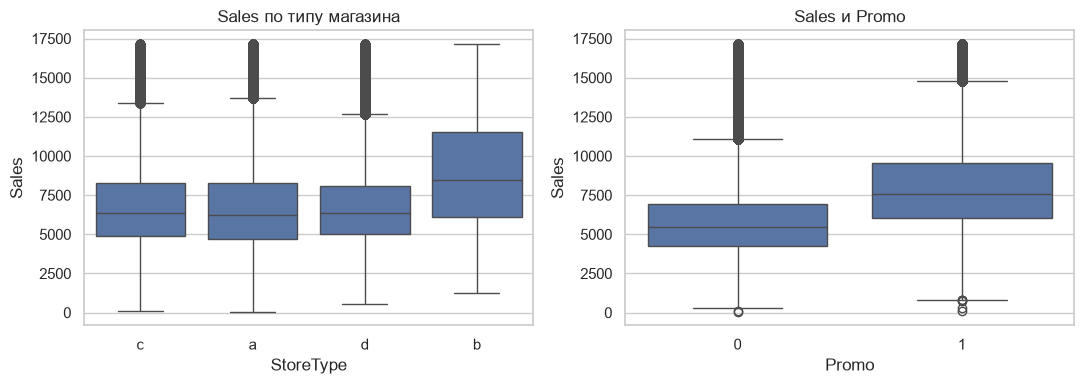

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=train_full.loc[(train_full["Sales"] > 0) & (train_full["Sales"] <= train_full["Sales"].quantile(0.99))],
            x="StoreType", y="Sales", ax=ax[0])
ax[0].set_title("Sales по типу магазина")
sns.boxplot(data=train.loc[(train["Sales"] > 0) & (train["Sales"] <= train["Sales"].quantile(0.99))],
            x="Promo", y="Sales", ax=ax[1])
ax[1].set_title("Sales и Promo")
plt.tight_layout()
plt.show()

## 5. Временная структура

Проверяются сезонность, частота продаж по дням недели и изменения показателей во времени. Конкурсная тестовая выборка относится к более позднему периоду.

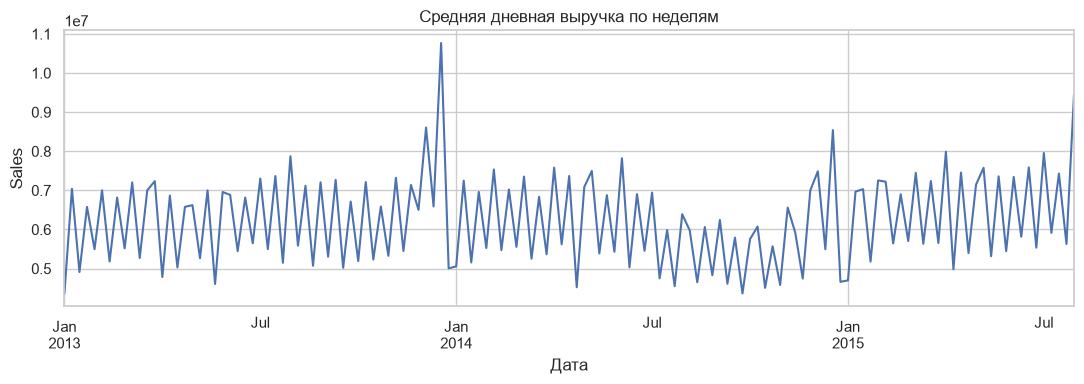

In [19]:
daily = train.groupby("Date")["Sales"].sum().sort_index()
fig, ax = plt.subplots(figsize=(11, 4))
daily.resample("W").mean().plot(ax=ax)
ax.set_title("Средняя дневная выручка по неделям")
ax.set_ylabel("Sales")
ax.set_xlabel("Дата")
plt.tight_layout()
plt.show()

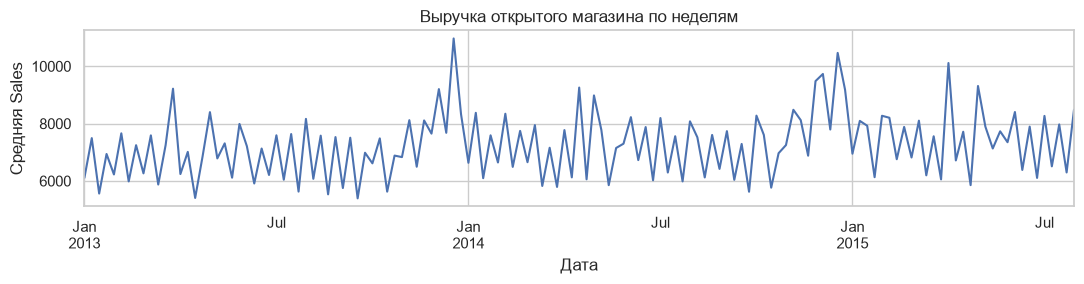

In [20]:
# Средняя выручка только по открытым магазинам.
daily_open = train.loc[train["Open"] == 1].groupby("Date")["Sales"].mean().sort_index()
daily_open.resample("W").mean().plot(figsize=(11, 3), title="Выручка открытого магазина по неделям")
plt.ylabel("Средняя Sales")
plt.xlabel("Дата")
plt.tight_layout()
plt.show()

Выручка по дням недели:


,size,median,mean
DayOfWeek,,,
1,144730,7310.0,7809.04
2,145664,6463.0,7005.24
3,145665,6133.0,6555.88
4,145845,6020.0,6247.58
5,145845,6434.0,6723.27
6,144730,5410.0,5847.56
7,144730,0.0,204.18


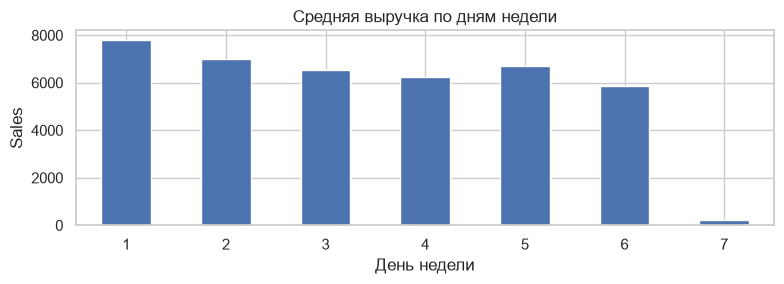

In [21]:
print("Выручка по дням недели:")
display(train.groupby("DayOfWeek")["Sales"].agg(["size", "median", "mean"]).round(2))
train.groupby("DayOfWeek")["Sales"].mean().plot.bar(figsize=(8, 3), rot=0, title="Средняя выручка по дням недели")
plt.xlabel("День недели")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

In [22]:
print("Выручка открытых магазинов по дням недели:")
display(train.loc[train["Open"] == 1].groupby("DayOfWeek")["Sales"]
        .agg(["size", "median", "mean"]).round(2))

Выручка открытых магазинов по дням недели:


,size,median,mean
DayOfWeek,,,
1,137560,7539.0,8216.07
2,143961,6502.0,7088.11
3,141936,6210.0,6728.12
4,134644,6246.0,6767.31
5,138640,6580.0,7072.68
6,144058,5425.0,5874.84
7,3593,6876.0,8224.72


,days,rows,sales_mean,promo_share
Month,,,,
2014-08,31,28985,5649.421,0.355
2014-09,30,28050,5865.104,0.400
2014-10,31,28985,5665.565,0.419
2014-11,30,28050,6179.250,0.500
2014-12,31,28985,6973.282,0.323
2015-01,31,34565,5752.748,0.484
2015-02,28,31220,5710.297,0.357
2015-03,31,34565,5949.130,0.387
2015-04,30,33450,5916.858,0.400


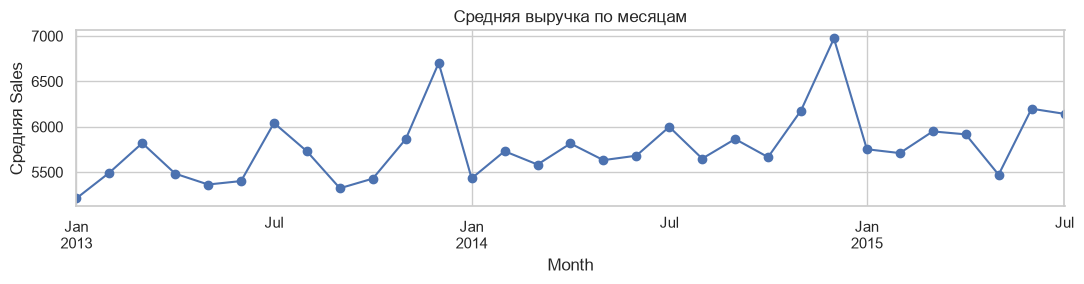

In [23]:
monthly = train.assign(Month=train["Date"].dt.to_period("M"))
monthly_stats = monthly.groupby("Month").agg(days=("Date", "nunique"),
                                               rows=("Sales", "size"),
                                               sales_mean=("Sales", "mean"),
                                               promo_share=("Promo", "mean"))
display(monthly_stats.tail(12).round(3))
monthly_stats["sales_mean"].plot(figsize=(11, 3), marker="o", title="Средняя выручка по месяцам")
plt.ylabel("Средняя Sales")
plt.tight_layout()
plt.show()

In [24]:
print("Охват отдельных магазинов:")
coverage = train.groupby("Store")["Date"].agg(["min", "max", "nunique"])
display(coverage["nunique"].describe().round(2))
print("Дата последней транзакции train:", train["Date"].max())
print("Первая дата test:", test["Date"].min())
print("Календарных дней между периодами:",
      (test["Date"].min() - train["Date"].max()).days - 1)

Охват отдельных магазинов:


count    1115.00
mean      912.30
std        67.73
min       758.00
25%       942.00
50%       942.00
75%       942.00
max       942.00
Name: nunique, dtype: float64

Дата последней транзакции train: 2015-07-31 00:00:00
Первая дата test: 2015-08-01 00:00:00
Календарных дней между периодами: 0


In [26]:
stores_by_month = train.groupby(train["Date"].dt.to_period("M"))["Store"].nunique()
print("Магазинов в каждом месяце (минимум и максимум):",
      stores_by_month.min(), stores_by_month.max())
print("Месяцы с неполным охватом магазинов:")
display(stores_by_month[stores_by_month < train["Store"].nunique()].to_frame("Магазинов"))
print("Несоответствий между датой и DayOfWeek в train:",
      (train["Date"].dt.day_of_week + 1 != train["DayOfWeek"]).sum())

Магазинов в каждом месяце (минимум и максимум): 935 1115
Месяцы с неполным охватом магазинов:


,Магазинов
Date,
2014-07,935
2014-08,935
2014-09,935
2014-10,935
2014-11,935
2014-12,935


Несоответствий между датой и DayOfWeek в train: 0


## 6. Доступность признаков на момент прогноза

Для прогноза будущих продаж необходимо учитывать информацию, доступную до начала прогнозируемого дня. Проверяются фактическое количество покупателей, сведения о будущих акциях и даты появления конкурентов.

In [27]:
print("Корреляция Sales с Customers:",
      round(train[["Sales", "Customers"]].corr().loc["Sales", "Customers"], 3))
print("Столбцы train, отсутствующие в test:", sorted(set(train.columns) - set(test.columns)))
print("Столбцы test, отсутствующие в train:", sorted(set(test.columns) - set(train.columns)))

Корреляция Sales с Customers: 0.895
Столбцы train, отсутствующие в test: ['Customers', 'Sales']
Столбцы test, отсутствующие в train: ['Id']


In [28]:
print("Год начала Promo2 позже даты наблюдения:",
      ((train_full["Promo2"] == 1) &
       (train_full["Promo2SinceYear"] > train_full["Date"].dt.year)).sum())
print("Год открытия конкурента позже даты наблюдения:",
      (train_full["CompetitionOpenSinceYear"] > train_full["Date"].dt.year).sum())
print("Неизвестный год начала конкуренции:",
      train_full["CompetitionOpenSinceYear"].isna().sum())

Год начала Promo2 позже даты наблюдения: 41607
Год открытия конкурента позже даты наблюдения: 52554
Неизвестный год начала конкуренции: 323348


In [29]:
# Проверка месяца открытия конкурента, если год и месяц указаны.
known = train_full["CompetitionOpenSinceYear"].notna() & train_full["CompetitionOpenSinceMonth"].notna()
competitor_open = pd.to_datetime(dict(year=train_full.loc[known, "CompetitionOpenSinceYear"].astype(int),
                                      month=train_full.loc[known, "CompetitionOpenSinceMonth"].astype(int),
                                      day=1), errors="coerce")
print("Строк с датой открытия конкурента позднее наблюдения:",
      (competitor_open > train_full.loc[known, "Date"]).sum())

Строк с датой открытия конкурента позднее наблюдения: 84666


In [30]:
# Расчёт начала Promo2 по ISO-неделе, без использования будущих продаж.
known = ((train_full["Promo2"] == 1) & train_full["Promo2SinceYear"].notna() &
         train_full["Promo2SinceWeek"].notna())
years = train_full.loc[known, "Promo2SinceYear"].astype(int).astype(str)
weeks = train_full.loc[known, "Promo2SinceWeek"].astype(int).astype(str).str.zfill(2)
promo_start = pd.to_datetime(years + weeks + "1", format="%G%V%u", errors="coerce")
print("Строк с началом Promo2 позднее наблюдения:",
      (promo_start > train_full.loc[known, "Date"]).sum())

Строк с началом Promo2 позднее наблюдения: 69630


## 7. Сравнение train/test

Проверяются совпадение схем, периоды наблюдений, пропуски и изменение распределений доступных признаков. В `test.csv` нет фактической выручки.

In [31]:
common = sorted((set(train.columns) & set(test.columns)) - {"Date"})
missing_compare = pd.DataFrame({
    "train, %": (100 * train[common].isna().mean()).round(2),
    "test, %": (100 * test[common].isna().mean()).round(2)
})
missing_compare["разница, п.п."] = (missing_compare["test, %"] - missing_compare["train, %"]).round(2)
display(missing_compare.reindex(missing_compare["разница, п.п."].abs().sort_values(ascending=False).index))

,"train, %","test, %","разница, п.п."
Open,0.0,0.03,0.03
DayOfWeek,0.0,0.00,0.00
Promo,0.0,0.00,0.00
SchoolHoliday,0.0,0.00,0.00
StateHoliday,0.0,0.00,0.00
Store,0.0,0.00,0.00


In [32]:
for col in ["Promo", "StateHoliday", "SchoolHoliday", "DayOfWeek", "Open"]:
    comp = pd.DataFrame({
        "train, %": (100 * train[col].value_counts(normalize=True, dropna=False)).round(2),
        "test, %": (100 * test[col].value_counts(normalize=True, dropna=False)).round(2)
    }).fillna(0)
    print("\n", col)
    display(comp)


 Promo


,"train, %","test, %"
Promo,,
0,61.85,60.42
1,38.15,39.58



 StateHoliday


,"train, %","test, %"
StateHoliday,,
0,96.95,99.56
a,1.99,0.44
b,0.66,0.00
c,0.40,0.00



 SchoolHoliday


,"train, %","test, %"
SchoolHoliday,,
0,82.14,55.65
1,17.86,44.35



 DayOfWeek


,"train, %","test, %"
DayOfWeek,,
1,14.23,14.58
2,14.32,14.58
3,14.32,14.58
4,14.34,14.58
5,14.34,12.50
6,14.23,14.58
7,14.23,14.58



 Open


,"train, %","test, %"
Open,,
0.0,16.99,14.56
1.0,83.01,85.41
NaN,0.00,0.03


In [33]:
print("Магазины без описания в store, train:",
      (~train["Store"].isin(store["Store"])).sum())
print("Магазины без описания в store, test:",
      (~test["Store"].isin(store["Store"])).sum())
print("Записей test без Open:", test["Open"].isna().sum())

Магазины без описания в store, train: 0
Магазины без описания в store, test: 0
Записей test без Open: 11


In [34]:
train_stores = set(train["Store"])
test_stores = set(test["Store"])
print("Общих магазинов train/test:", len(train_stores & test_stores))
print("Магазинов только в train:", len(train_stores - test_stores))
print("Доля обучающих записей для магазинов из test, %:",
      round(100 * train["Store"].isin(test_stores).mean(), 2))
print("Распределение типов магазинов по участию в test, %:")
display((100 * pd.crosstab(store["StoreType"], store["Store"].isin(test_stores),
                             normalize="columns")).round(2).rename(columns={False: "Нет в test", True: "Есть в test"}))

Общих магазинов train/test: 856
Магазинов только в train: 259
Доля обучающих записей для магазинов из test, %: 76.01
Распределение типов магазинов по участию в test, %:


Store,Нет в test,Есть в test
StoreType,,
a,54.44,53.86
b,1.93,1.40
c,22.78,10.40
d,20.85,34.35


## 8. Связи признаков с продажами

Исследуются основные числовые зависимости. Корреляция не подтверждает причинную связь и не означает доступность признака при прогнозировании.

,Корреляция с Sales
Sales,1.000
Customers,0.895
Promo,0.452
SchoolHoliday,0.085
CompetitionDistance,-0.019
DayOfWeek,-0.462


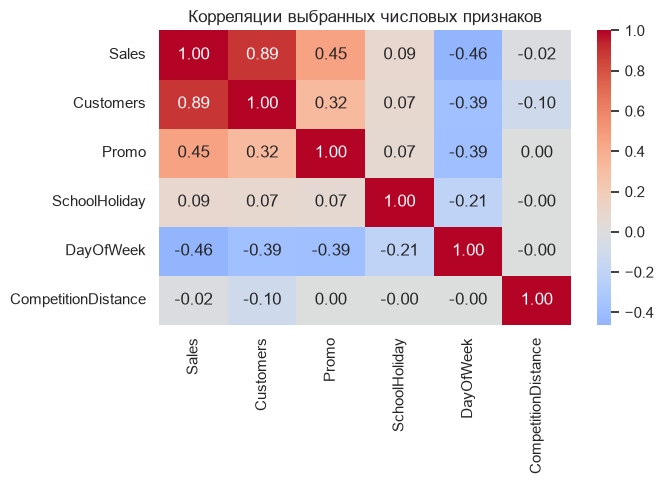

In [35]:
features = ["Sales", "Customers", "Promo", "SchoolHoliday", "DayOfWeek", "CompetitionDistance"]
correlations = train_full[features].corr(numeric_only=True)
display(correlations["Sales"].sort_values(ascending=False).to_frame("Корреляция с Sales").round(3))
plt.figure(figsize=(7, 5))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции выбранных числовых признаков")
plt.tight_layout()
plt.show()

In [36]:
print("Медианные продажи по сочетанию Open и Promo:")
display(train.groupby(["Open", "Promo"])["Sales"].agg(["size", "median", "mean"]).round(2))

Медианные продажи по сочетанию Open и Promo:


size  median     mean
Open Promo                         
0    0      161633     0.0     0.00
     1       11184     0.0     0.00
1    0      467496  5459.0  5929.41
     1      376896  7649.0  8228.28

## 9. Риски утечек и ограничения

`Customers` отражает фактическое число покупателей за прогнозируемый день и отсутствует в `test.csv`. Использование этого признака для прогнозирования будущей выручки приводит к некорректной постановке задачи, если прогноз покупателей не доступен отдельно.

Сведения о начале участия в Promo2 и о появлении конкурента относятся к разным моментам времени. Даты начала после даты продаж не доказывают утечку сами по себе, но требуют восстановления доступного на тот день состояния признаков.

Для проверки будущих продаж требуется хронологическое разделение размеченной истории. Конкурсный `test.csv` не содержит `Sales`, поэтому не подходит для локального расчёта качества.

## 10. Выводы и эталон для агента

1. Тип задачи - регрессия, целевая переменная `Sales`.
2. Для прогноза будущего дня необходимо исключить `Customers` как фактический показатель этого дня.
3. Разделение для независимой оценки выполняется по времени, а не случайным перемешиванием дат.
4. Пропуски полей Promo2 и конкурентов рассматриваются с учётом особенностей работы магазина, а не только общего процента отсутствующих значений.
5. При присоединении `store.csv` проверяется уникальность ключа `Store` и историческая доступность признаков.
6. Подозрительные наблюдения, в том числе `Open=1` при нулевых продажах, требуют проверки до исправления или удаления.
7. Для сравнения train/test используются общие признаки и последовательные временные периоды; `test.csv` не используется для расчёта локального качества.